In [1]:
from anemone.forwards import ForwardMatrix, ForwardLaplace6
import torch
from numpy import ndarray
import matplotlib.pyplot as plt
import numpy as np

In [2]:
rho   = torch.tensor([20, 80, 40])
thick = torch.tensor([20, 30])

In [3]:
from anemone.experiment import Loop, Receiver, Waveform

t = torch.logspace(-5, -3, 40)
tx = Loop.square(40)
rx = Receiver()
waveform = Waveform.example()


In [4]:
fwr0 = ForwardLaplace6(tx, rx, t, waveform)
fwr1 = ForwardMatrix(tx, rx, t, waveform)
dbdt = fwr1(rho,thick)
G1 = fwr1(rho, thick, jac=True)

c:\users\au646858\onedrive - aarhus universitet\documents\_repositories\anemone\src\anemone\experiment\experiment.py:129: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  return torch.tensor(overall_min)


shape of lambda:  torch.Size([301])


In [5]:
fwr1 = ForwardMatrix(tx, rx, t, waveform)

shape of lambda:  torch.Size([301])
shape of lambda:  torch.Size([301])


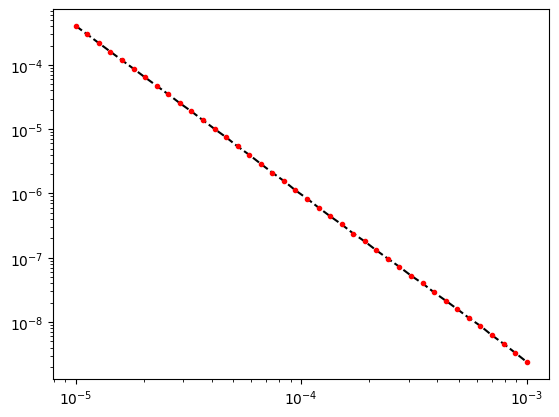

In [6]:
rho = torch.ones(31, dtype=torch.double)*40.
rho[5:10] = 20.
rho[25:27] = 90.

thick = torch.logspace(-1, 1.2, len(rho)-1, dtype=torch.double)
dbdt0 = fwr0(rho, thick)
dbdt1 = fwr1(rho, thick)

plt.figure()
plt.loglog(fwr0.times, dbdt0, 'k--')
plt.loglog(fwr1.times, dbdt1, 'r.')

In [7]:
# %%timeit
# dbdt1 = fwr1(rho, thick)

In [8]:
# %%timeit
dm = rho*0.02
rho_mat = rho[:, None] + torch.eye(len(rho))*dm
#if 'dbdt_mat' not in locals():
dbdt_mat = fwr0(rho_mat, thick)
G0 = (dbdt_mat - dbdt0[None, :]) / dm[:, None]
# G0 = G0.numpy()

In [9]:
fwr1 = ForwardMatrix(tx, rx, t, waveform)
dbdt = fwr1(rho, thick)
G1 = fwr1(rho, thick, jac=True)

shape of lambda:  torch.Size([301])


In [10]:
from dolphinv import Tikhonov
from anemone.inversion import *

times = torch.logspace(-5,-2, 32)

ImportError: cannot import name 'Tikhonov' from 'dolphinv' (C:\Users\au646858\OneDrive - Aarhus Universitet\Documents\_repositories\dolphinv\src\dolphinv\__init__.py)

In [ ]:
def compute_relstd(t_gates, dbdt, noise_slope_exponent=-0.5, noise_level_at_1ms=1e-8, current=1., relative_noise=0.03):
    b = noise_level_at_1ms/(1e-3**noise_slope_exponent)
    abs_noise = b*(t_gates**noise_slope_exponent)
    y = dbdt*current
    std_rel = abs_noise/y
    relstd_tot = torch.sqrt(std_rel**2 + relative_noise**2)
    return relstd_tot

In [ ]:
def logify_forward(cls):
    class LogFwr(cls):
        def __call__(self, *args, **kwargs):
            if not kwargs.get('jac', False):
                return super().__call__(*args, **kwargs).log10()
            else:
                return super().__call__(*args, **kwargs)
    return LogFwr

LFL6 = logify_forward(ForwardMatrix)

In [ ]:
fwr1 = LFL6(tx, rx, times, waveform=waveform)

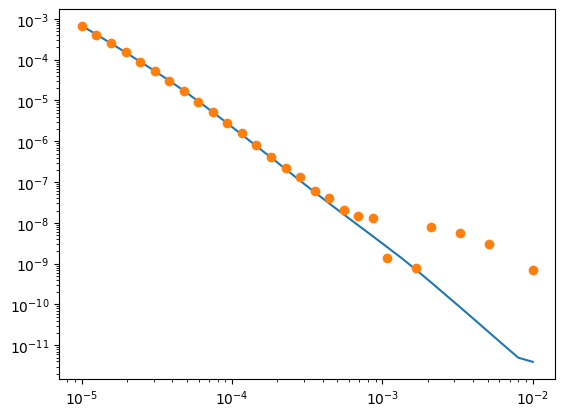

In [ ]:
rho = torch.tensor([20, 100, 40])
thk = torch.tensor([30,40.])
mod_true = LogResistivity.few_layers(rho, thk)


dbdt_true = 10**fwr1(rho, thk)
d_relerr = compute_relstd(fwr1.times, dbdt_true, current=1.)
d_err = torch.log10(1. + d_relerr)

d_obs = dbdt_true + dbdt_true * torch.randn_like(dbdt_true) * d_relerr
#d_err = dbdt_true*d_relerr

plt.figure()
plt.loglog(fwr1.times, dbdt_true, '-', label='Observed')
plt.loglog(fwr1.times, d_obs, 'o', label='Observed')

d_obs = torch.abs(d_obs).log10()

In [ ]:
class TikhoJacobian(Tikhonov):
    def jacobian(self, mvec):
        rho,thick = self.model.modelize(mvec)
        G = self.forward(rho, thick, jac=True)
        G *= rho[:,None]
        G /= 10**self.data_predicted
        return G.T

001	misfit:	5.92
002	misfit:	1.34
002	misfit:	1.34
003	misfit:	0.87
004	misfit:	0.81
003	misfit:	0.87
004	misfit:	0.81
005	misfit:	0.79
005	misfit:	0.79
006	misfit:	0.78
006	misfit:	0.78
007	misfit:	0.77
007	misfit:	0.77
008	misfit:	0.76
008	misfit:	0.76
009	misfit:	0.75
009	misfit:	0.75
010	misfit:	0.73
reached iteration cap..
010	misfit:	0.73
reached iteration cap..


[<Axes: title={'center': 'resistivity'}, ylabel='depth [m]'>]

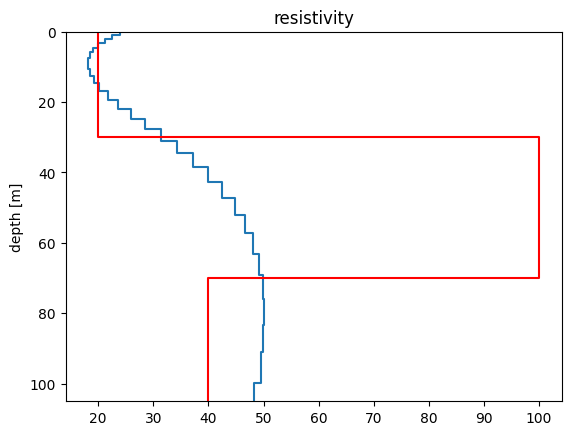

In [ ]:
torch.set_num_threads(8)

fwr1 = LFL6(tx, rx, times, waveform=waveform)

thick = torch.logspace(0,1,30)
z = torch.cumsum(thick, 0)

res_start = LogResistivity.smooth(torch.ones(len(z)+1, dtype=torch.double)*50., z)
inv = TikhoJacobian(d_obs, d_err, res_start, fwr1)
inv.vertical_smoothness = 1e-2

res_mod = inv.invert(iter_cap=10)
ax = res_mod.plot()
mod_true.plot(axs=ax, color='red', label='True model')

shape of data is : torch.Size([100, 32])


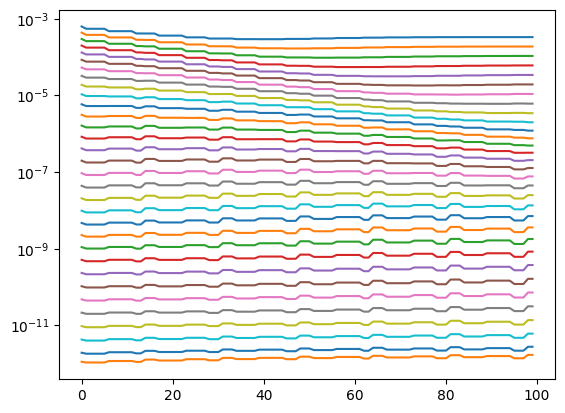

In [ ]:
import matplotlib.pyplot as plt

from anemone.experiment import Loop, Receiver, compute_relstd, Waveform
tx = Loop.square(40)
rx = Receiver()
t = torch.logspace(-5, -2, 32, dtype=torch.double)


gpu = torch.device('cpu')
LFM = logify_forward(ForwardMatrix)
fwr = LFM(tx, rx, t.to(gpu), waveform=Waveform.example())

n_layers = len(z)+1

n_mod = 100

z = np.arange(n_layers)[:,None]
x = (300/n_mod)*np.arange(n_mod)[None,:]

rho = 150*np.ones_like(z+x)
rho[(0.03*x-0.75*z+10)>0] = 10
rho[(0.075*x-1.25*z+5)>0] = 40

rho = torch.from_numpy(rho.astype(float)).to(gpu)
mtrues = [Resistivity.few_layers(r, thick) for r in rho.T]

dbdt = fwr(rho, thick)


print('shape of data is :', dbdt.shape)
# should be >>> shape of data is : torch.Size([10, 16])
plt.figure()
plt.semilogy(10**dbdt.cpu())
plt.show()

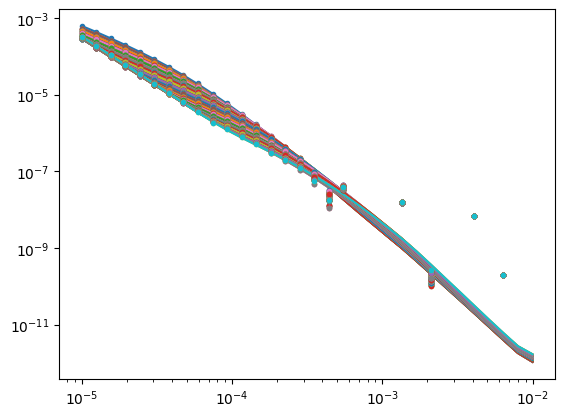

In [ ]:
n_data = len(dbdt.flatten())
dbdt_err = compute_relstd(fwr.times, 10**dbdt)
d_err = torch.log10(1. + dbdt_err)
d_obs = (10**dbdt) * ( 1. + torch.randn_like(dbdt_true) * dbdt_err)


plt.figure()
plt.loglog(fwr1.times, 10**dbdt.T, '-', label='Observed')
plt.loglog(fwr1.times, d_obs.T, '.', label='Observed')

d_obs = torch.abs(d_obs).log10()

In [ ]:
from torch import block_diag
from scipy.sparse import diags_array, sparray, coo_array, csr_array

class LCI(Inversion):
    log = print
    smoothness_vert = 1e2
    smoothness_lat  = 1e2
    max_step = 3.0
    diag_normalizer = 5e3
    damping_factor = 3.0

    def __init__(self, inv_list):
        self.inv_list = inv_list
        self.data_observed = torch.concat([inv.data_observed for inv in self.inv_list]).numpy()
        self.nD = len(self.data_observed)
        # self.data_observed = self.data_observed.to_sparse()

        self.data_error    = torch.concat([inv.data_error    for inv in self.inv_list]).numpy()
        self.recip_error_squared = (1. / self.data_error**2)#.to_sparse()
        self.damp_value = 2500.
        self.damp_reduction_factor = np.sqrt(2)
        self.iter_cap = 50
        self.misfits = [np.inf]
        self.NDamp = 6  # Initial damping exponent

    @property
    def m(self):
        return torch.concat([inv.m for inv in self.inv_list])

    def mforward(self, mvec):
        mvecs = mvec.reshape(len(self.inv_list), -1)
        datas = [inv.mforward(mv) for inv, mv in zip(self.inv_list, mvecs)]
        return torch.concat(datas).numpy()#to_sparse()

    def jacobian(self, mvec):
        mvecs = mvec.reshape(len(self.inv_list), -1)
        jacs = [inv.jacobian(mv).numpy() for inv, mv in zip(self.inv_list, mvecs)]
        return sparse_block_diag(jacs)
    
    def misfit(self):
        return np.sqrt(self.data_misfit().sum()/self.nD)
    
    def setup_matrices(self):
        self.mvec = self.m * 1.
        self.Cdi = diags_array(self.recip_error_squared)
        self.Imod = torch.eye(len(self.mvec)).to_sparse()
        self._current_mvec = self.mvec * 1.1 if torch.all(self.mvec != 0) else torch.ones_like(self.mvec)
        self._G = None
        self.iteration = 0
        self.misfits = [np.inf]
        self.misfits.append(self.misfit())
        # Block diagonal vertical smoothness
        self.H = sparse_block_diag([inv.model.H() for inv in self.inv_list])
        self.HtH = (self.H.T @ self.H) * self.smoothness_vert
        # Lateral smoothness
        n = len(self.mvec)
        m_per_inv = len(self.inv_list[0].m)
        RL = torch.eye(n, device=self.mvec.device) - torch.roll(torch.eye(n, device=self.mvec.device), -m_per_inv, dims=0)
        # RL[:, -2*m_per_inv:]=0.
        RL = RL[:-2*m_per_inv]
        self.LtL = (RL.T @ RL) * self.smoothness_lat
        self.LtL = csr_array(self.LtL.numpy())
        

    @property
    def G(self):
        if not hasattr(self, '_G') or self._G is None or torch.any(self.mvec != getattr(self, '_current_mvec', None)):
            self._G = self.jacobian(self.mvec)
            self._current_mvec = self.mvec * 1.
            self._GtG = self._G.T @ self.Cdi @ self._G
        return self._G

    @property
    def GtG(self):
        if not hasattr(self, '_GtG') or torch.any(self.mvec != getattr(self, '_current_mvec', None)):
            self._G = self.jacobian(self.mvec)
            self._current_mvec = self.mvec * 1.
            self._GtG = self._G.T @ self.Cdi @ self._G
        return self._GtG

    @property
    def damp_matrix(self):
        diag_GTG = self.GtG.diagonal()
        max_diag = diag_GTG.max() / self.diag_normalizer
        return sparse_eye(len(self.mvec)) * self.damp_value * float(max_diag)

    def calc_dm(self):
        r_data = self.G.T @ self.Cdi @ (self.data_observed - self.data_predicted)
        Aown = self.GtG + self.damp_matrix + self.HtH + self.LtL
        return torch.from_numpy(spsolve(Aown, r_data))

    def run_iteration(self):
        dM = self.calc_dm()
        self.damp_value /= self.damp_reduction_factor
        self.mvec += torch.nan_to_num(dM)
        self.iteration += 1
        self.misfits.append(self.misfit())
        self.log("{:03d}\tmisfit:\t{:2.2f}".format(self.iteration, self.misfits[-1]))

    def invert(self, iter_cap=10, **kwargs):
        self.setup_matrices()
        self.iter_cap = iter_cap
        while not self.stop_inversion:
            self.run_iteration()
        # Split mvec back to each inversion
        mres_list = []
        mvecs = self.mvec.reshape(len(self.inv_list), -1)
        for inv, mvec in zip(self.inv_list, mvecs):
            mres = inv.model.copy()
            mres.values = mres.modelize(mvec)[:inv.model.n_ptypes]
            inv.model = mres
            mres_list.append(mres)
        return mres_list

In [ ]:
invs = []
for i in range(n_mod):
    inv = TikhoJacobian(d_obs[i], d_err[i], res_start.copy(), fwr)
    inv.vertical_smoothness = 1e1
    inv.setup_matrices()
    invs.append(inv)
lci = LCI(invs)
lci.smoothness_vert = 1e1
lci.smoothness_lat = 1e1
mres = lci.invert(iter_cap=10)

001	misfit:	4.38
002	misfit:	3.52
002	misfit:	3.52
003	misfit:	2.93
003	misfit:	2.93
004	misfit:	2.51
004	misfit:	2.51
005	misfit:	2.21
005	misfit:	2.21
006	misfit:	1.97
006	misfit:	1.97
007	misfit:	1.79
007	misfit:	1.79
008	misfit:	1.65
008	misfit:	1.65
009	misfit:	1.53
009	misfit:	1.53
010	misfit:	1.43
reached iteration cap..
010	misfit:	1.43
reached iteration cap..


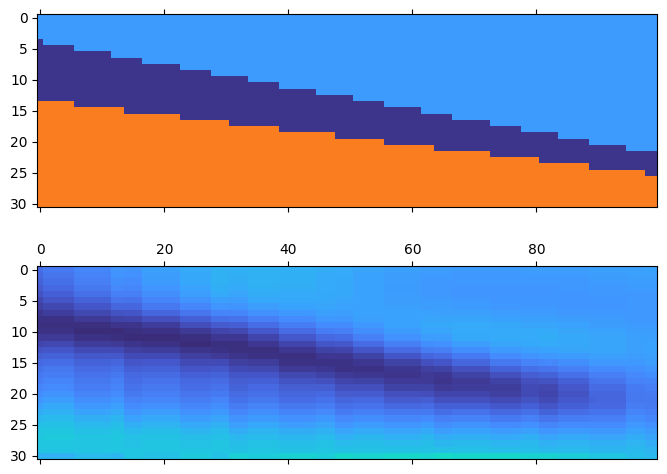

In [ ]:
rho_true = torch.stack([m.values[0] for m in mtrues])
rho_res = torch.stack([m.values[0] for m in mres])

fig,axs = plt.subplots(2,1, sharex=True, sharey=True, figsize=(8, 6))
axs[0].matshow(rho_true.cpu().numpy().T, cmap='turbo', vmin=0, vmax=200)
axs[1].matshow(rho_res.cpu().numpy().T, cmap='turbo', vmin=0, vmax=200)